<a href="https://colab.research.google.com/github/RaviPratapSingh-4/nirwana-wall-floor/blob/main/nirwana_wall_floor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Wall and floor mask generator (classical CV, no segmentation model)

Takes an interior photo and returns two pixel masks: one for walls, one for floor.
Everything here is superpixels, k-means, Gaussian colour models and a bit of geometry. No pre-trained or fine-tuned segmentation model and no segmentation API.

## Disclosure
- **AI help:** I used Claude (Anthropic) as a mentor and pair-programmer while building this: talking through the design, debugging, and drafting some of the code. I ran every experiment myself and the numbers below are the ones my runs produced.
- **Libraries:** NumPy, OpenCV, scikit-image (SLIC superpixels), scikit-learn (KMeans, GaussianMixture), SciPy, Matplotlib.
- **Tools:** labelme for ground-truth labels, Google Colab.
- **Images:** Unsplash interior photos. I hand-labelled 6 of them, plus one sample image (dev01) that came with masks.

**How to run:** Runtime > Run all. Section 5 at the bottom lets you upload your own photo.

## 1. Setup

In [1]:
import os, glob, time, json, shutil, cv2, numpy as np, matplotlib.pyplot as plt

# my labelled images live in a public GitHub repo so this runs on a fresh runtime
REPO = "https://github.com/RaviPratapSingh-4/nirwana-wall-floor.git"   # <- put the public repo link here

if not os.path.exists("data/labeled"):
    !git clone -q {REPO} repo
    !cp -r repo/data data
print(len(glob.glob("data/labeled/*")), "files in data/labeled")

15 files in data/labeled


## 2. The pipeline
Pipeline in short: shrink the image, cut it into superpixels, cluster the superpixels to find the wall, then build the floor from a colour model.

In [2]:
from skimage.segmentation import slic
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from scipy import ndimage as ndi

def small(im, L=384):
    # work at 384px on the long side, it's much faster and the masks are upsampled at the end
    s = L / max(im.shape[:2])
    return cv2.resize(im, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)

def superpixel_features(s, n=300):
    # one feature vector per superpixel: mean Lab colour, brightness spread (texture), and position
    H, W = s.shape[:2]
    lab = cv2.cvtColor(s, cv2.COLOR_RGB2LAB).astype(np.float32)
    sp = slic(s, n_segments=n, compactness=10, start_label=0)
    i, m = sp.ravel(), sp.max() + 1
    yy, xx = np.mgrid[:H, :W]
    c = np.maximum(np.bincount(i, minlength=m), 1)
    mean = lambda a: np.bincount(i, a.ravel(), m) / c
    L = lab[..., 0]
    sd = np.sqrt(np.maximum(mean(L**2) - mean(L)**2, 0))
    f = np.stack([mean(lab[..., 0]), mean(lab[..., 1]), mean(lab[..., 2]), sd, mean(yy / H), mean(xx / W)], 1)
    return sp, (f - f.mean(0)) / (f.std(0) + 1e-6)

def upsample(m, img):
    return cv2.resize(m.astype(np.uint8), img.shape[1::-1], interpolation=cv2.INTER_NEAREST) > 0

def floor_v1(s, sp, band=.12, q=.9, excl=None, disc=False, top=.35):
    # floor colour model: fit a 3-component GMM on the bottom strip of the image,
    # then call a superpixel floor if it fits that model well enough
    H, W = s.shape[:2]
    lab = cv2.cvtColor(s, cv2.COLOR_RGB2LAB).astype(np.float32)
    flat = lab.reshape(-1, 3)
    strip = np.zeros((H, W), bool); strip[int(H * (1 - band)):] = True
    if excl is not None: strip &= ~excl          # don't learn "floor" colour from wall pixels
    seed = lab[strip]
    if len(seed) < 300: return np.zeros((H, W), bool)
    i, m = sp.ravel(), sp.max() + 1
    cnt = np.maximum(np.bincount(i, minlength=m), 1)
    gm = GaussianMixture(3, random_state=0).fit(seed)
    ll = gm.score_samples(flat).reshape(H, W)
    thr = np.quantile(gm.score_samples(seed), 1 - q)
    spl = np.bincount(i, ll.ravel(), m) / cnt
    ok = spl > thr
    if disc:
        # extra check: it must also fit the floor model BETTER than a model of the top of the image (walls)
        topx = lab[:int(H * top)].reshape(-1, 3)[::4]
        gmt = GaussianMixture(3, random_state=0).fit(topx)
        lt = gmt.score_samples(flat).reshape(H, W)
        ok &= spl > np.bincount(i, lt.ravel(), m) / cnt
    lb, _ = ndi.label(ok[sp])
    keep = np.unique(lb[-1][lb[-1] > 0])         # keep only blobs that touch the bottom edge
    return np.isin(lb, keep)

def fill_hull(fl, min_area=.02):
    # fill the convex hull of each big floor blob, this is what recovers rugs
    cnts, _ = cv2.findContours(fl.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    h = np.zeros(fl.shape, np.uint8)
    for c in cnts:
        if cv2.contourArea(c) > min_area * fl.size: cv2.fillPoly(h, [cv2.convexHull(c)], 1)
    return h.astype(bool)

def segment(img, k=8, hull=True, wall_first=False, disc=False, merge=0, q=.9, band=.12):
    s = small(img)
    sp, f = superpixel_features(s)
    H, W = sp.shape
    km = KMeans(k, n_init=3, random_state=0).fit(f)
    cl = km.labels_[sp]
    ctr = km.cluster_centers_[:, :3]
    yy = np.repeat((np.arange(H) / H)[:, None], W, axis=1)
    area = np.array([(cl == j).mean() for j in range(k)])
    my = np.array([yy[cl == j].mean() if (cl == j).any() else 1.0 for j in range(k)])

    def pick_wall(fl):
        # wall = biggest cluster that sits in the upper part of the image (and isn't mostly floor)
        ov = np.array([(fl & (cl == j)).sum() / max((cl == j).sum(), 1) for j in range(k)]) if fl is not None else np.zeros(k)
        cand = [j for j in range(k) if area[j] > .03 and ov[j] < .2 and my[j] < .6]
        if not cand: return np.zeros((H, W), bool)
        wl = max(cand, key=lambda j: area[j])
        ids = [wl]
        if merge > 0:
            # one wall often gets split by shading, so pull in clusters with a similar colour
            ids += [j for j in range(k) if j != wl and area[j] > .01 and my[j] < .6
                    and np.linalg.norm(ctr[j] - ctr[wl]) < merge]
        return np.isin(cl, ids)

    if wall_first:
        wall = pick_wall(None)
        fl = floor_v1(s, sp, excl=wall, disc=disc, q=q, band=band)
    else:
        fl = floor_v1(s, sp, disc=disc, q=q, band=band)
        wall = pick_wall(fl)
    if hull: fl = fill_hull(fl) & ~wall
    return upsample(wall, img), upsample(fl & ~wall, img)

def floor_guard(pw, pf, maxfrac=.30, rows=.15):
    # if "floor" covers more than 30% of the frame the colour seed was probably wrong
    # (bed / sofa / white wall at the bottom), so only trust the bottom 15% of rows
    if pf.mean() <= maxfrac: return pw, pf
    out = pf.copy(); out[:int(pf.shape[0] * (1 - rows))] = False
    return pw, out

def segment_final(img):
    return floor_guard(*segment(img, wall_first=True, disc=True, merge=1.0))

## 3. Ground truth and metrics

In [3]:
np.set_printoptions(suppress=True, precision=3)
iou  = lambda p, g: (p & g).sum() / max((p | g).sum(), 1)
dice = lambda p, g: 2 * (p & g).sum() / max(p.sum() + g.sum(), 1)
prec = lambda p, g: (p & g).sum() / max(p.sum(), 1)
rec  = lambda p, g: (p & g).sum() / max(g.sum(), 1)
imread = lambda p: cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
gt = lambda p, s: cv2.resize(cv2.imread(p, 0), s[1::-1], interpolation=cv2.INTER_NEAREST) > 127

def json2masks(folder="data/labeled"):
    # labelme json -> _wall.png / _floor.png  (wall_hole = windows, curtains etc. cut out of the wall)
    for jp in sorted(glob.glob(f"{folder}/*.json")):
        d = json.load(open(jp)); H, W = d["imageHeight"], d["imageWidth"]
        m = {k: np.zeros((H, W), np.uint8) for k in ("wall", "floor", "wall_hole")}
        for s in d["shapes"]:
            if s["label"] not in m: continue
            pts = np.round(np.array(s["points"])).astype(np.int32)
            if s.get("shape_type", "polygon") == "rectangle":
                (x1, y1), (x2, y2) = pts
                pts = np.array([[x1, y1], [x2, y1], [x2, y2], [x1, y2]], np.int32)
            cv2.fillPoly(m[s["label"]], [pts], 255)
        wall = m["wall"].copy(); wall[m["wall_hole"] > 0] = 0
        b = os.path.splitext(jp)[0]
        cv2.imwrite(b + "_wall.png", wall); cv2.imwrite(b + "_floor.png", m["floor"])

def labeled_images(folder="data/labeled"):
    out = []
    for p in sorted(glob.glob(f"{folder}/*")):
        b = os.path.splitext(p)[0]
        if b.endswith(("_wall", "_floor")) or p.endswith(".json"): continue
        if os.path.exists(b + "_wall.png") and os.path.exists(b + "_floor.png"): out.append((p, b))
    return out

def overlay(img, m, col):
    o = img.copy(); o[m] = (.5 * o[m] + .5 * np.array(col)).astype(np.uint8); return o

def errmap(img, p, g):
    o = img.copy(); o[p & ~g] = (255, 0, 0); o[~p & g] = (0, 0, 255); return o

def show(img, pw, pf, gf, title=""):
    fig, ax = plt.subplots(1, 4, figsize=(20, 4)); [a.axis("off") for a in ax]
    ax[0].imshow(img); ax[0].set_title(title)
    ax[1].imshow(overlay(img, pw, (255, 0, 0))); ax[1].set_title("wall")
    ax[2].imshow(overlay(img, pf, (0, 0, 255))); ax[2].set_title("floor")
    ax[3].imshow(errmap(img, pf, gf)); ax[3].set_title("floor errors: red = extra, blue = missed"); plt.show()

def evaluate(fn, name, plot=False, per_image=False):
    res = []
    for p, b in labeled_images():
        img = imread(p); gw, gf = gt(b + "_wall.png", img.shape), gt(b + "_floor.png", img.shape)
        t = time.perf_counter(); pw, pf = fn(img); ms = (time.perf_counter() - t) * 1e3
        r = (iou(pw, gw), dice(pw, gw), iou(pf, gf), dice(pf, gf), prec(pf, gf), rec(pf, gf), ms); res.append(r)
        if per_image:
            print(f"  {os.path.basename(b)[:14]:14} wall IoU {r[0]:.2f} (GT {gw.mean():.2f} pred {pw.mean():.2f})"
                  f" | floor IoU {r[2]:.2f} (GT {gf.mean():.2f} pred {pf.mean():.2f}) | {ms:.0f} ms")
        if plot: show(img, pw, pf, gf, f"{os.path.basename(b)}  wall {r[0]:.2f}  floor {r[2]:.2f}")
    print(f"{name} [wallIoU wallDice floorIoU floorDice floorPrec floorRec ms]:", np.round(np.mean(res, 0), 3))
    return np.array(res)

json2masks()
print(len(labeled_images()), "labelled images ready")

7 labelled images ready


## 4. Experiments
Labelling rule I used: a rug counts as floor; windows, curtains, cabinets, ceiling and furniture are not wall and not floor.
Each version adds one idea on top of the previous one.

In [4]:
print("--- v1: GMM floor, no hull")
evaluate(lambda im: segment(im, hull=False), "v1")
print("--- v2: + convex hull for rugs")
evaluate(lambda im: segment(im), "v2")
print("--- v3: + wall picked first, floor must beat a wall colour model, similar wall clusters merged")
evaluate(lambda im: segment(im, wall_first=True, disc=True, merge=1.0), "v3", per_image=True)
print("--- final: v3 + floor guard")
evaluate(segment_final, "final", per_image=True);

--- v1: GMM floor, no hull
v1 [wallIoU wallDice floorIoU floorDice floorPrec floorRec ms]: [   0.325    0.446    0.324    0.439    0.455    0.777 1076.578]
--- v2: + convex hull for rugs
v2 [wallIoU wallDice floorIoU floorDice floorPrec floorRec ms]: [  0.325   0.446   0.362   0.454   0.438   0.899 813.417]
--- v3: + wall picked first, floor must beat a wall colour model, similar wall clusters merged
  arto-suraj-MQX wall IoU 0.41 (GT 0.71 pred 0.32) | floor IoU 0.11 (GT 0.06 pred 0.53) | 1137 ms
  clay-banks-UTW wall IoU 0.48 (GT 0.36 pred 0.53) | floor IoU 0.26 (GT 0.08 pred 0.29) | 890 ms
  collov-home-de wall IoU 0.58 (GT 0.41 pred 0.41) | floor IoU 0.64 (GT 0.20 pred 0.19) | 742 ms
  dev01          wall IoU 0.90 (GT 0.28 pred 0.26) | floor IoU 0.81 (GT 0.26 pred 0.22) | 872 ms
  jessica-martin wall IoU 0.61 (GT 0.52 pred 0.42) | floor IoU 0.06 (GT 0.03 pred 0.45) | 790 ms
  minh-pham-OtXA wall IoU 0.64 (GT 0.38 pred 0.34) | floor IoU 0.70 (GT 0.21 pred 0.16) | 877 ms
  vojtech-bru

In [5]:
# how much to merge wall clusters? (colour distance between k-means centres)
for m in [.8, 1.0, 1.2, 1.6, 2.0]:
    evaluate(lambda im, m=m: segment(im, wall_first=True, disc=True, merge=m), f"merge={m}")

merge=0.8 [wallIoU wallDice floorIoU floorDice floorPrec floorRec ms]: [   0.514    0.659    0.39     0.497    0.472    0.888 1079.105]
merge=1.0 [wallIoU wallDice floorIoU floorDice floorPrec floorRec ms]: [   0.606    0.745    0.391    0.499    0.474    0.888 1243.648]
merge=1.2 [wallIoU wallDice floorIoU floorDice floorPrec floorRec ms]: [   0.56     0.715    0.39     0.498    0.477    0.884 1062.846]
merge=1.6 [wallIoU wallDice floorIoU floorDice floorPrec floorRec ms]: [   0.548    0.705    0.382    0.493    0.503    0.86  1081.763]
merge=2.0 [wallIoU wallDice floorIoU floorDice floorPrec floorRec ms]: [   0.536    0.692    0.381    0.492    0.503    0.8   1132.016]


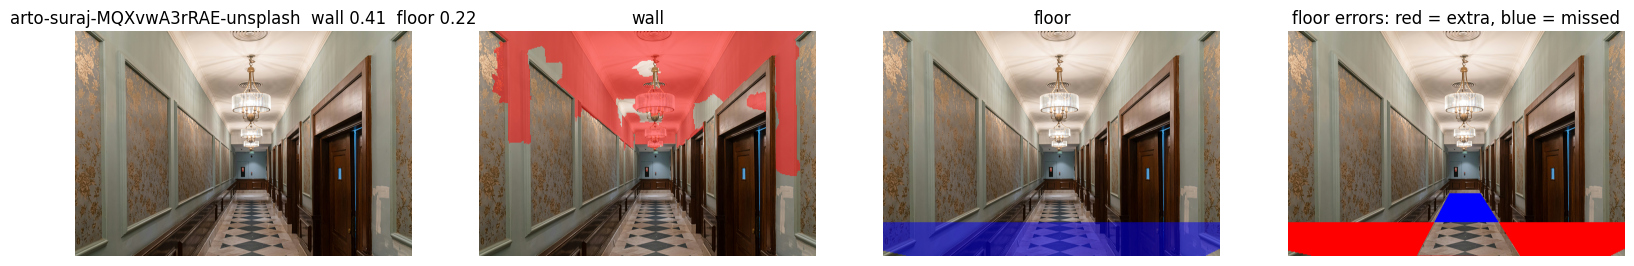

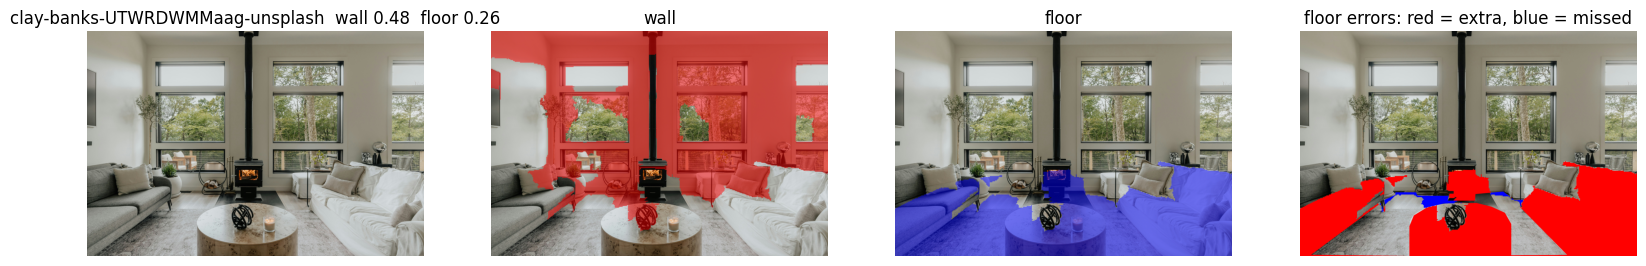

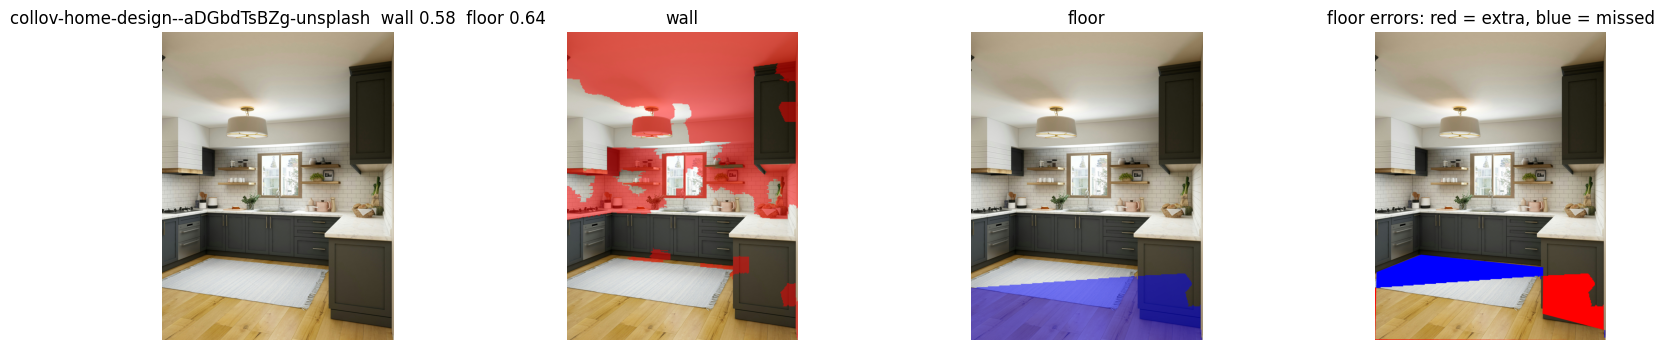

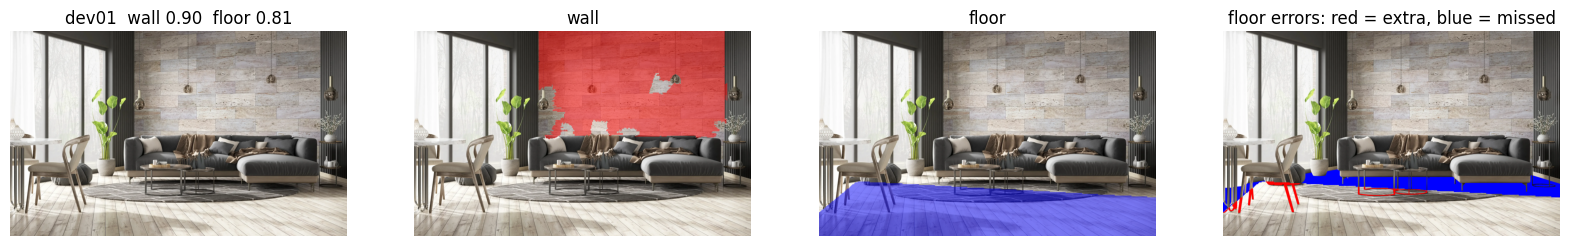

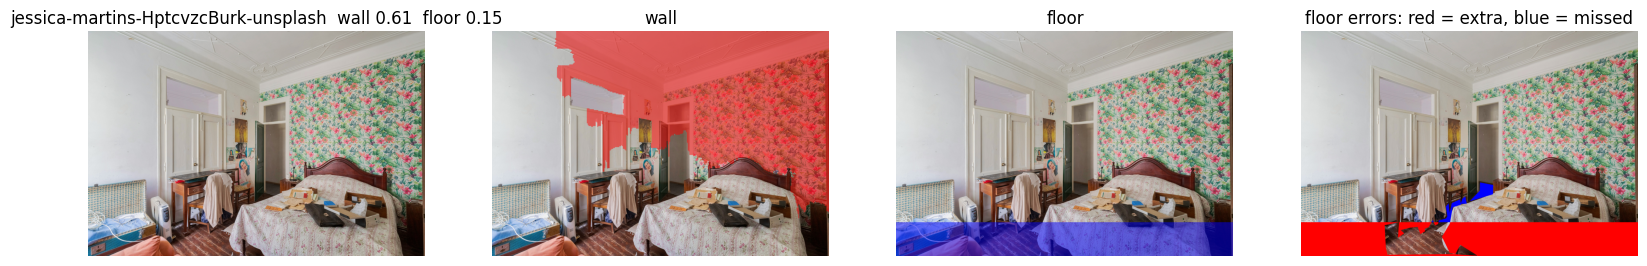

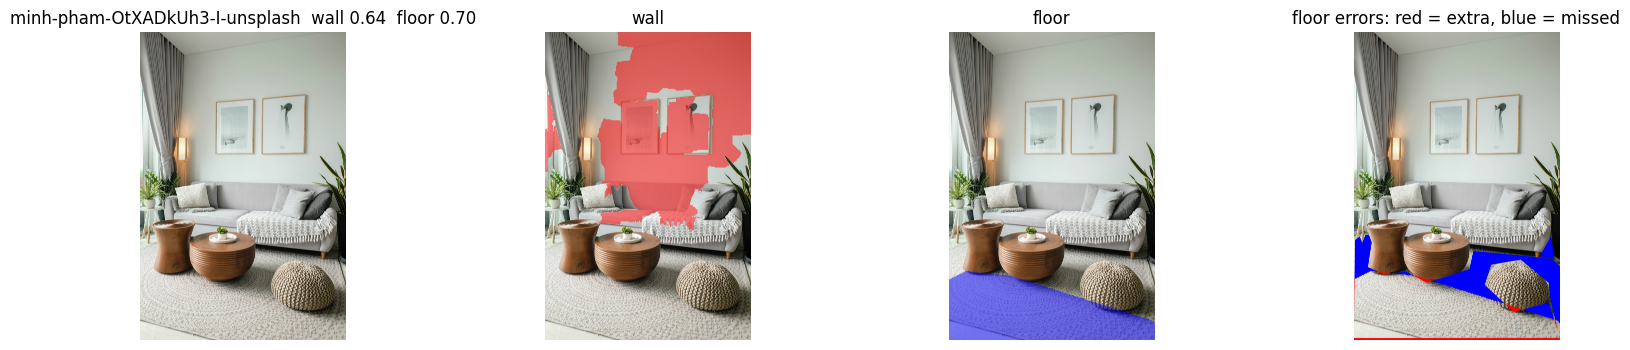

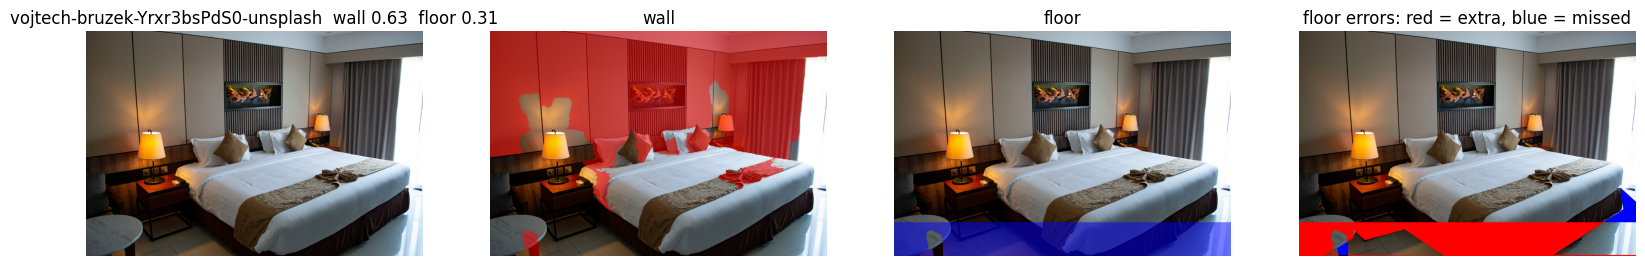

final [wallIoU wallDice floorIoU floorDice floorPrec floorRec ms]: [   0.606    0.745    0.442    0.574    0.532    0.801 1014.561]


In [6]:
# what the final pipeline actually produces on every labelled image
evaluate(segment_final, "final", plot=True);

In [7]:
# speed and memory for the final pipeline (median of 5 runs, Colab CPU timing is noisy)
import tracemalloc
img = imread(labeled_images()[0][0]); ts = []
for _ in range(5):
    t = time.perf_counter(); segment_final(img); ts.append((time.perf_counter() - t) * 1e3)
tracemalloc.start(); segment_final(img); peak = tracemalloc.get_traced_memory()[1] / 1e6; tracemalloc.stop()
print(f"median {np.median(ts):.0f} ms over 5 runs, peak python/numpy memory {peak:.0f} MB")

median 1160 ms over 5 runs, peak python/numpy memory 67 MB


### What I measured (7 images: 6 hand-labelled + dev01)

| Version | Wall IoU | Floor IoU |
|---|---|---|
| v1: GMM floor model | .325 | .324 |
| v2: + convex hull (rugs) | .325 | .362 |
| v3: + wall-first, floor-vs-wall colour test, wall cluster merging | .606 | .391 |
| final: + floor guard | .606 | .442 |

- Merging similar wall clusters was the biggest wall gain: a single wall gets split by shading, so the biggest cluster alone is only part of it.
- The hull fixed the dark rug on dev01 (floor IoU .654 to .808) but it also swallows chair legs.
- Tried and dropped because they had no measurable effect: vertical morphological closing, tuning the likelihood quantile and seed-strip height, and a "floor must be below the wall base" rule.

### Limitations (being honest about them)
- Only 7 images, and I picked the settings on those same images, so the numbers are optimistic. dev01 is an easy scene (wall IoU .90).
- Merge distance matters: at 1.2 dev01's wall IoU drops from .90 to .58, so over-merging is a real risk on unseen images.
- The floor model is colour-only. When only a thin strip of floor is visible and the bottom of the frame is a bed, sofa or white wall base (jessica, vojtech, arto), it floods the frame. The guard limits the damage but doesn't fix it. A geometric cue (the wall-floor edge via Hough lines or vanishing points) would be the next thing to try.
- The convex hull assumes one convex floor, so L-shaped floors and hallways can go wrong.
- Walls with strong texture (floral wallpaper, panelled hallway) are under-segmented.
- Not tested yet: photos with no wall or no floor at all.

## 5. Try your own image

Saving roberto-nickson-emqnSQwQQDo-unsplash.jpg to roberto-nickson-emqnSQwQQDo-unsplash.jpg


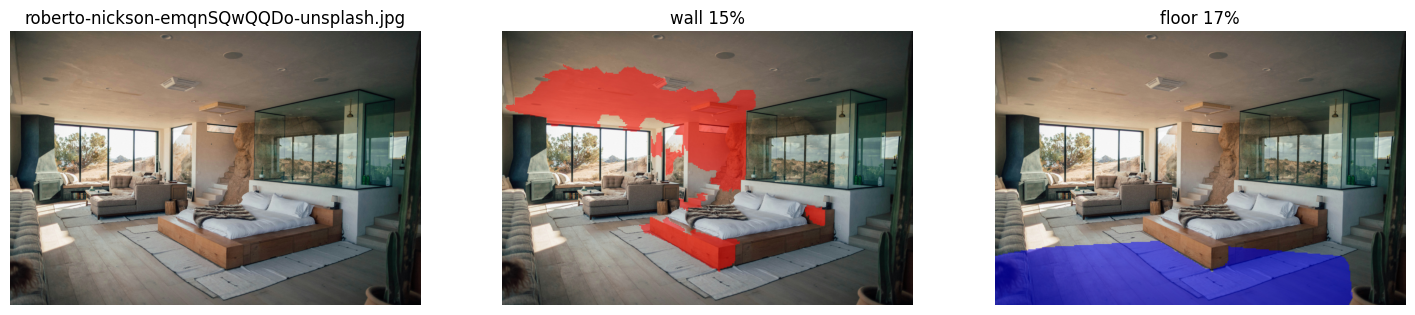

(3648, 5472)  median 1012 ms


In [8]:
from google.colab import files
up = files.upload()
for name in up:
    img = imread(name); ts = []
    for _ in range(3):
        t = time.perf_counter(); pw, pf = segment_final(img); ts.append((time.perf_counter() - t) * 1e3)
    fig, ax = plt.subplots(1, 3, figsize=(18, 5)); [a.axis("off") for a in ax]
    ax[0].imshow(img); ax[0].set_title(name)
    ax[1].imshow(overlay(img, pw, (255, 0, 0))); ax[1].set_title(f"wall {pw.mean():.0%}")
    ax[2].imshow(overlay(img, pf, (0, 0, 255))); ax[2].set_title(f"floor {pf.mean():.0%}")
    plt.show()
    print(f"{img.shape[:2]}  median {np.median(ts):.0f} ms")
    stem = os.path.splitext(name)[0]
    cv2.imwrite(stem + "_wall_mask.png", pw.astype(np.uint8) * 255)
    cv2.imwrite(stem + "_floor_mask.png", pf.astype(np.uint8) * 255)